# Clasificación de conversaciones con XGBoost

Las etiquetas de `ML/tf_idf_matrix_clases.csv` las genera `auto_label.py` con reglas de palabras clave. Por eso las features se construyen aquí **desde el mismo texto** que leen las reglas (`mensajes_processed.txt`), con el mismo `normalize`, y no desde `output/tf_idf_matrix.csv`: esa matriz elimina saludos y cortesías (`ok`, `gracias`, `hola`…) que definen `Confirmación_Estado` e `Interacción/Relacional`.

> **Importante:** el F1 contra estas etiquetas mide qué tan bien el modelo **reproduce las reglas**, no si acierta el tema real. La exactitud real se mide al final, contra `ML/muestra_etiquetado.csv` etiquetado a mano.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import workspace
workspace.set_workspace_path(os.getcwd())
import auto_label
import conv_classifier

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

RANDOM_STATE = conv_classifier.RANDOM_STATE
FEATURES = conv_classifier.FEATURES
N_GOLD = 150         # chats separados para etiquetado manual
GOLD_PATH = conv_classifier.get_gold_path()

## Datos
Texto de cada chat normalizado igual que en las reglas. Se excluyen los chats `No Clasificado` (sin señales) y los vacíos.

In [2]:
data = conv_classifier.load_dataset()
total = len(data)

data = data[(data["Clase"] != auto_label.SIN_CLASE) & (data["texto"] != "")].reset_index(drop=True)
print("Chats utilizables:", len(data), "de", total)
data["Clase"].value_counts()

Chats utilizables: 898 de 913


Clase
Gestión de Pedidos/Entregas    239
Facturación_Documentos         181
Confirmación_Estado            168
Cotización/Presupuesto         154
Interacción/Relacional         127
Seguimiento de Ventas           13
Consulta de Precio               8
Cancelación                      5
Soporte                          3
Name: count, dtype: int64

In [3]:
raras = conv_classifier.get_rare_classes(data["Clase"])
agrupar = lambda c: "Otras" if c in raras else c
print("Agrupadas en 'Otras':", sorted(raras))

data["y_raw"] = data["Clase"].map(agrupar)
le = LabelEncoder()
data["y"] = le.fit_transform(data["y_raw"])
data["y_raw"].value_counts()

Agrupadas en 'Otras': ['Cancelación', 'Consulta de Precio', 'Seguimiento de Ventas', 'Soporte']


y_raw
Gestión de Pedidos/Entregas    239
Facturación_Documentos         181
Confirmación_Estado            168
Cotización/Presupuesto         154
Interacción/Relacional         127
Otras                           29
Name: count, dtype: int64

## Muestra para etiquetado manual
Se separa antes de entrenar y **nunca** se usa para entrenar. Se exporta a `ML/muestra_etiquetado.csv` solo si no existe, para no sobrescribir lo que ya hayas etiquetado: llena la columna `Clase_manual` con la clase correcta de cada chat.

In [4]:
if os.path.exists(GOLD_PATH):
    gold_chats = set(pd.read_csv(GOLD_PATH, encoding="utf-8-sig")["Chat"])
    print("Usando la muestra existente:", GOLD_PATH)
else:
    _, gold = train_test_split(data, test_size=N_GOLD, stratify=data["y"], random_state=RANDOM_STATE)
    gold[["Chat", "texto", "Clase"]].rename(columns={"Clase": "Clase_regla"}).assign(Clase_manual="") \
        .to_csv(GOLD_PATH, index=False, encoding="utf-8-sig")
    gold_chats = set(gold["Chat"])
    print("Muestra exportada:", GOLD_PATH)

rest = data[~data["Chat"].isin(gold_chats)]
print("Chats para entrenar/evaluar:", len(rest))

Usando la muestra existente: C:\ws\SalesAnalyzer\ML\muestra_etiquetado.csv
Chats para entrenar/evaluar: 748


## Pipeline con XGBoost
TF-IDF de unigramas y bigramas sobre el texto + número de mensajes, seguido de `XGBClassifier`. El desbalance de clases se compensa con `sample_weight`.

El pipeline está definido en `conv_classifier.py`, que es el mismo que usa la etapa `-classify` de `main.py`.

In [5]:
# hiperparametros base (los de antes del grid search); los mejores quedan como default en conv_classifier.XGB_PARAMS
pipe = conv_classifier.build_pipeline(n_estimators=300, max_depth=6, n_jobs=1)

X, y = rest[FEATURES], rest["y"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pipe.fit(X_tr, y_tr, xgb__sample_weight=compute_sample_weight("balanced", y_tr))
y_pred = pipe.predict(X_te)

print(classification_report(y_te, y_pred, target_names=le.classes_, zero_division=0))
print("F1 macro:", round(f1_score(y_te, y_pred, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.76      0.79      0.77        28
     Cotización/Presupuesto       0.75      0.81      0.78        26
     Facturación_Documentos       0.80      0.80      0.80        30
Gestión de Pedidos/Entregas       0.69      0.68      0.68        40
     Interacción/Relacional       0.79      0.90      0.84        21
                      Otras       0.00      0.00      0.00         5

                   accuracy                           0.75       150
                  macro avg       0.63      0.66      0.65       150
               weighted avg       0.73      0.75      0.74       150

F1 macro: 0.646


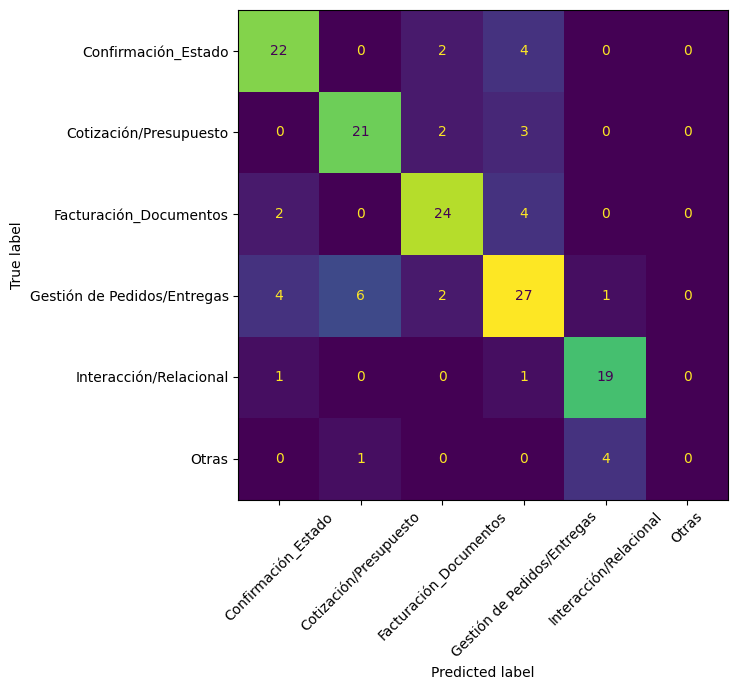

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=le.classes_).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

## Validación cruzada estratificada (5 folds)

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_cv = cross_val_predict(pipe, X, y, cv=skf, n_jobs=-1,
                         params={"xgb__sample_weight": compute_sample_weight("balanced", y)})
print(classification_report(y, y_cv, target_names=le.classes_, zero_division=0))
print("F1 macro (CV):", round(f1_score(y, y_cv, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.71      0.83      0.77       140
     Cotización/Presupuesto       0.82      0.77      0.79       128
     Facturación_Documentos       0.80      0.75      0.77       151
Gestión de Pedidos/Entregas       0.70      0.67      0.69       199
     Interacción/Relacional       0.74      0.91      0.81       106
                      Otras       0.50      0.12      0.20        24

                   accuracy                           0.75       748
                  macro avg       0.71      0.67      0.67       748
               weighted avg       0.74      0.75      0.74       748

F1 macro (CV): 0.672


## Grid Search
Búsqueda de hiperparámetros con validación cruzada sobre el train set, optimizando F1 macro. El test set solo se usa al final. Si encuentras mejores hiperparámetros, actualiza `XGB_PARAMS` en `conv_classifier.py`.

In [8]:
param_grid = {
    "xgb__max_depth":        [3, 6],
    "xgb__learning_rate":    [0.05, 0.1],
    "xgb__n_estimators":     [200, 400],
    "xgb__colsample_bytree": [0.3, 0.5],
    "xgb__min_child_weight": [1, 3],
}

grid = GridSearchCV(
    pipe, param_grid,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, refit=True, verbose=1,
)

t0 = time.time()
grid.fit(X_tr, y_tr, xgb__sample_weight=compute_sample_weight("balanced", y_tr))
print(f"Tiempo: {time.time() - t0:.0f}s")
print("Mejores parámetros:", grid.best_params_)
print("F1 macro (CV, train):", round(grid.best_score_, 3))

Fitting 5 folds for each of 32 candidates, totalling 160 fits


Tiempo: 260s
Mejores parámetros: {'xgb__colsample_bytree': 0.5, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 3, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 200}
F1 macro (CV, train): 0.691


In [9]:
res = pd.DataFrame(grid.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
res[cols].sort_values("mean_test_score", ascending=False).head(10)

,param_xgb__colsample_bytree,param_xgb__learning_rate,param_xgb__max_depth,param_xgb__min_child_weight,param_xgb__n_estimators,mean_test_score,std_test_score
24,0.5,0.10,3,1,200,0.691495,0.037737
17,0.5,0.05,3,1,400,0.690812,0.036216
16,0.5,0.05,3,1,200,0.689038,0.041300
8,0.3,0.10,3,1,200,0.679429,0.037149
25,0.5,0.10,3,1,400,0.678637,0.056793
0,0.3,0.05,3,1,200,0.669105,0.035107
28,0.5,0.10,6,1,200,0.666750,0.035208
1,0.3,0.05,3,1,400,0.666623,0.027029
18,0.5,0.05,3,3,200,0.665518,0.043050
9,0.3,0.10,3,1,400,0.665475,0.049918


In [10]:
best = grid.best_estimator_
y_pred_best = best.predict(X_te)

print(classification_report(y_te, y_pred_best, target_names=le.classes_, zero_division=0))
print("F1 macro test  — base:", round(f1_score(y_te, y_pred, average="macro"), 3),
      "| grid:", round(f1_score(y_te, y_pred_best, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.81      0.79      0.80        28
     Cotización/Presupuesto       0.81      0.85      0.83        26
     Facturación_Documentos       0.79      0.87      0.83        30
Gestión de Pedidos/Entregas       0.78      0.70      0.74        40
     Interacción/Relacional       0.77      0.95      0.85        21
                      Otras       0.00      0.00      0.00         5

                   accuracy                           0.79       150
                  macro avg       0.66      0.69      0.67       150
               weighted avg       0.77      0.79      0.77       150

F1 macro test  — base: 0.646 | grid: 0.674


## Features más importantes

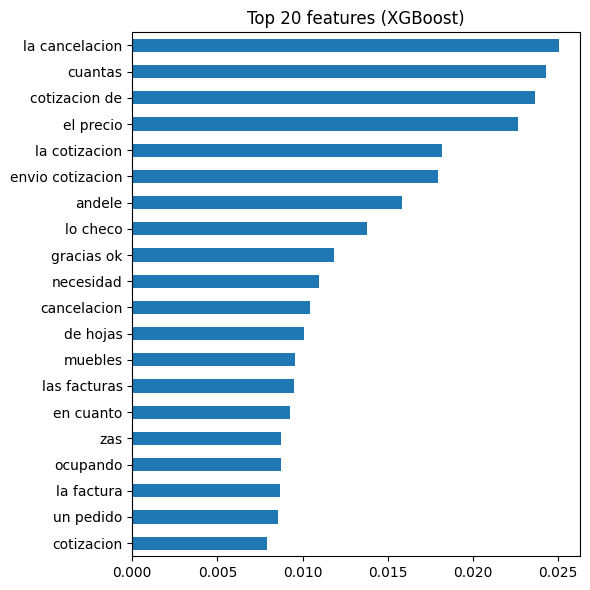

In [11]:
names = best.named_steps["feats"].get_feature_names_out()
imp = pd.Series(best.named_steps["xgb"].feature_importances_, index=names).nlargest(20)
imp.index = imp.index.str.replace(r"^\w+?__", "", regex=True)
imp[::-1].plot.barh(figsize=(6, 6), title="Top 20 features (XGBoost)")
plt.tight_layout(); plt.show()

## Evaluación real contra etiquetas manuales
Compara las **reglas** y el **modelo** contra `Clase_manual`. Solo se usan las filas que ya tengan etiqueta.

In [12]:
gold_df = pd.read_csv(GOLD_PATH, encoding="utf-8-sig").merge(data[["Chat", "n_msgs"]], on="Chat")
gold_df = gold_df[gold_df["Clase_manual"].fillna("").astype(str).str.strip() != ""]

if gold_df.empty:
    print(f"Aún no hay etiquetas manuales. Llena la columna Clase_manual en {GOLD_PATH} y vuelve a ejecutar esta celda.")
else:
    manual = gold_df["Clase_manual"].str.strip().map(agrupar)
    regla = gold_df["Clase_regla"].map(agrupar)
    modelo = le.inverse_transform(best.predict(gold_df[FEATURES]))
    print(f"Chats etiquetados a mano: {len(gold_df)}\n")
    print("Reglas vs manual  — F1 macro:", round(f1_score(manual, regla, average="macro"), 3),
          "| accuracy:", round((manual == regla).mean(), 3))
    print("Modelo vs manual  — F1 macro:", round(f1_score(manual, modelo, average="macro"), 3),
          "| accuracy:", round((manual == modelo).mean(), 3))
    print("\nModelo vs manual:")
    print(classification_report(manual, modelo, zero_division=0))

Aún no hay etiquetas manuales. Llena la columna Clase_manual en C:\ws\SalesAnalyzer\ML\muestra_etiquetado.csv y vuelve a ejecutar esta celda.
